In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import build_model, halofit
from astropy.stats import sigma_clip
from mytools.data import read_h5, vitems

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

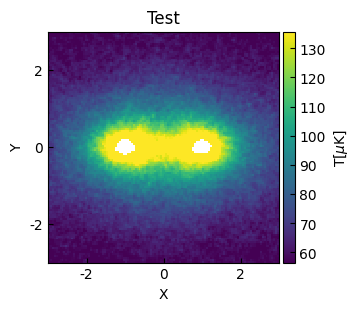

In [3]:
data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=5, masked=True)
plot_heatmap(data, title='Test')

In [4]:
coord = get_coord()

name = 'nfw'
bg_name = 'poly'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.5),
    'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        ("r_s_1", "r_s_2"),
        ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

# init_bg = {
#     "degree": 1
# }

model = build_model(name, bg_name,bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Polynomial2D(1, c0_0=0., c1_0=0., c0_1=0., x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=0., c1_0=0., c0_1=0., x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... c0_1_2 c0_0_3 c1_0_3 c0_1_3
    ----------- -------- -------- ----- ... ------ ------ ------ ------
           50.0     -1.0      0.0   0.5 ...    0.0    0.0    0.0    0.0


In [5]:
# pixcount weight
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
vitems(weight_path)

Item: crafts_122k
Type: Group
Attributes (0):
 None
Item: crafts_122k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: crafts_122k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_120k
Type: Group
Attributes (0):
 None
Item: tng_120k/npair
Type: Dataset
Shape: ()
Dtype: int64
Attributes (0):
 None
Item: tng_120k/pixcount
Type: Dataset
Shape: (21, 120, 120)
Dtype: int64
Attributes (0):
 None
Item: tng_120k/weight
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None


<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

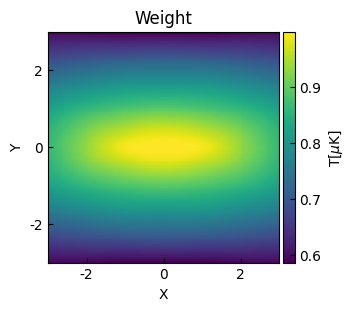

In [6]:
weights = read_h5(weight_path, 'tng_120k/weight')
plot_heatmap(weights, title='Weight', q=0.1)

# without mask

In [7]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True, weights=weights)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.55986144, x_mean=-1., y_mean=0., r_s=79.74170321, ellipticity=0.32605584, theta=-0.01801093)>

    [1]: <NFW2D(amplitude=0.55986144, x_mean=1., y_mean=0., r_s=77.41809495, ellipticity=0.32605584, theta=-0.00558554)>

    [2]: <Polynomial2D(1, c0_0=-115.5651984, c1_0=410.71673283, c0_1=23.15137944, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=-115.5651984, c1_0=-410.33718959, c0_1=-23.43843374, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       c1_0_3             c0_1_3      
    ------------------ -------- -------- ... ----------------- -------------------
    0.5598614426016124     -1.0      0.0 ... -410.337189593732 -23.438433744845348

Goodness of fit:
Chi-squared: 298870.482
RMS residual: 4.572


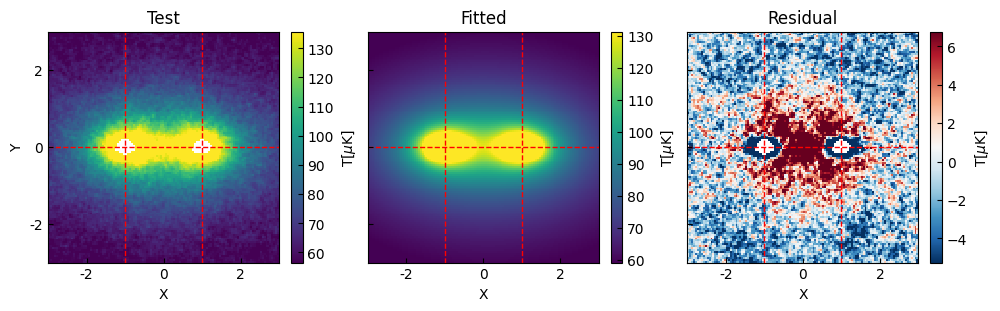

In [8]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

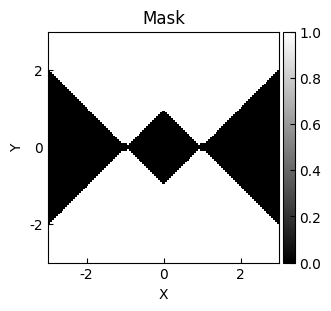

In [9]:
# mask = get_mask_sector(coord=coord)
mask = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [10]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True, weights=weights[mask])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.47029521, x_mean=-1., y_mean=0., r_s=121.96514445, ellipticity=0.49988728, theta=-0.01201754)>

    [1]: <NFW2D(amplitude=0.47029521, x_mean=1., y_mean=0., r_s=117.22098775, ellipticity=0.49988728, theta=-0.02183324)>

    [2]: <Polynomial2D(1, c0_0=-182.77769018, c1_0=610.50816933, c0_1=-0.16881179, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=-182.77769018, c1_0=-610.19389266, c0_1=-0.16894354, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0     x_mean_0 y_mean_0 ...       c1_0_3              c0_1_3      
    ------------------- -------- -------- ... ------------------ -------------------
    0.47029521021509146     -1.0      0.0 ... -610.1938926639066 -0.1689435419986779

Goodness of fit:
Chi-squared: 795153.758
RMS residual: 7.458


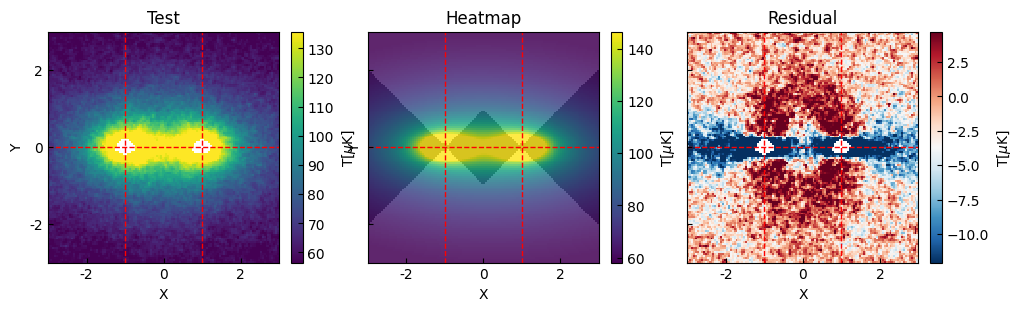

In [11]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

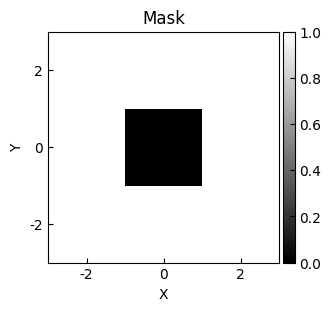

In [12]:
mask = ~get_mask_square(coord=coord)
# mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [13]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True, weights=weights[mask])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.48259963, x_mean=-1., y_mean=0., r_s=88.91958604, ellipticity=0.30130946, theta=-0.0281804)>

    [1]: <NFW2D(amplitude=0.48259963, x_mean=1., y_mean=0., r_s=86.30359412, ellipticity=0.30130946, theta=-0.02562215)>

    [2]: <Polynomial2D(1, c0_0=-132.78189944, c1_0=461.77285947, c0_1=-0.16157744, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=-132.78189944, c1_0=-461.40057824, c0_1=-0.16160486, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       c1_0_3             c0_1_3      
    ------------------ -------- -------- ... ----------------- -------------------
    0.4825996321851504     -1.0      0.0 ... -461.400578242554 -0.1616048555705065

Goodness of fit:
Chi-squared: 314614.841
RMS residual: 4.691


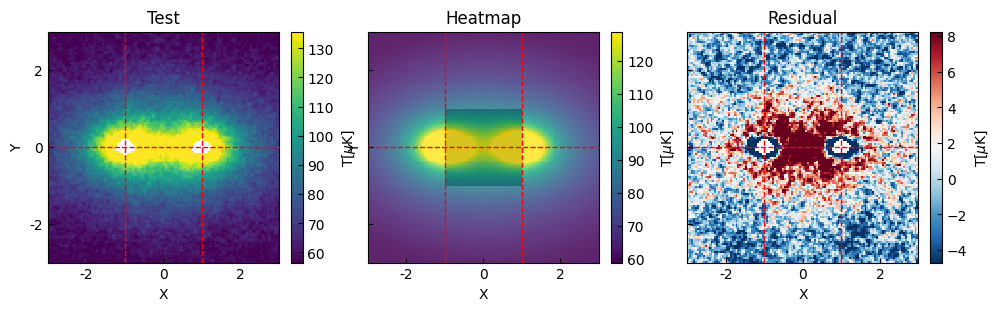

In [14]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [15]:
from mytools.plot import plot_hist

(-100.0, 100.0)

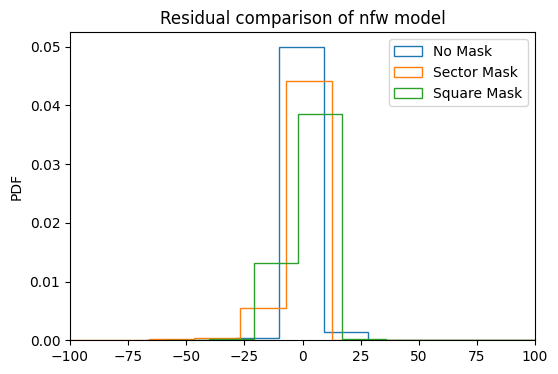

In [16]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [26]:
from mytools.plot import plot_line_diff, make_figure

In [18]:
# stack_fit_res = data_list_sector
# stack_fit_res = data_list_square
stack_fit_res = data_list

In [24]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'x=1']

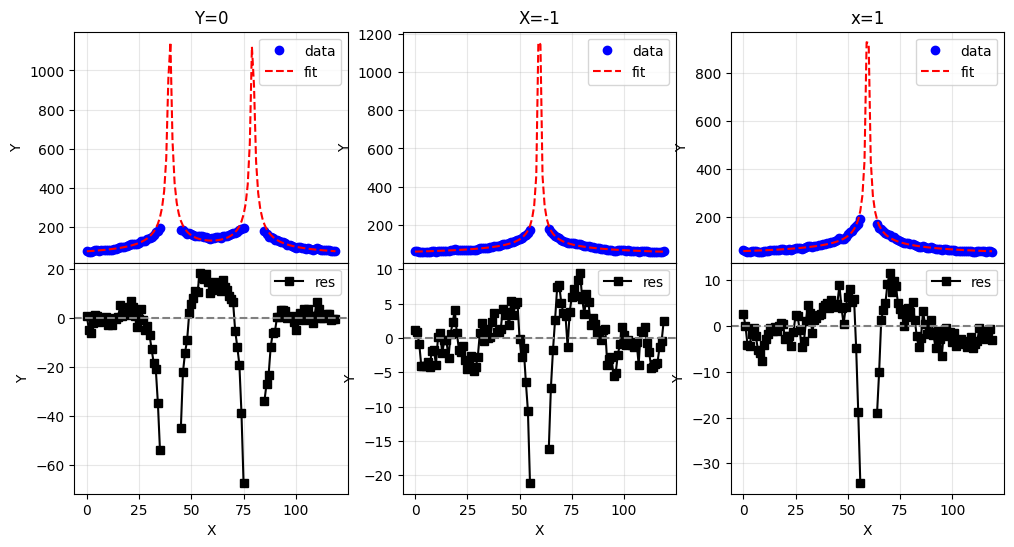

In [27]:
fig, axes = make_figure(2,3, figsize=(12,6),wspace=0.2, hspace=0.,aspect=None,sharex=True, sharey=False)

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

# estimate signal level

In [20]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(11.018844350491998), np.float64(0.0), np.float64(0.6606394322123175), np.float64(-0.8803136007240747)]
Gauss fit covariance: 
[[ 0.09095968 -0.00053364 -0.03048118]
 [-0.00053364  0.00062471 -0.00309959]
 [-0.03048118 -0.00309959  0.03972087]]
0 points clipped during sigma clipping.
width: 0.6606394322123175
width_pix: 13


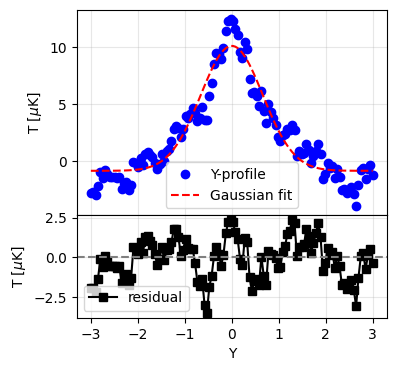

In [28]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0, 0.7),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

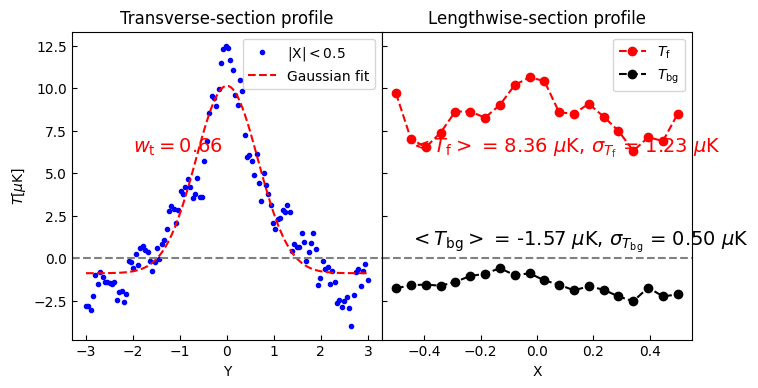

In [29]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

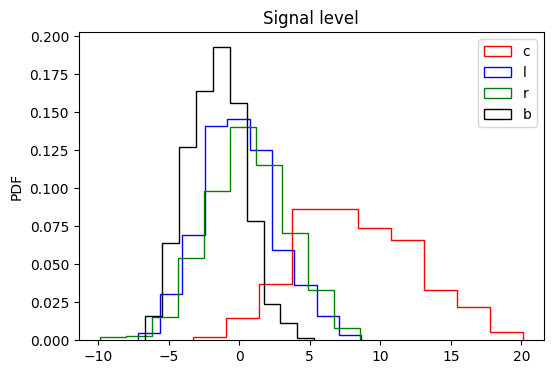

In [30]:
plot_hist(clrb, label=['c','l','r','b'], color=['r', 'b','g','k'], title='Signal level')